# 06 · Predictive Modelling
**Milestone 6 — Kenyan Retail Customer & Sales Intelligence Capstone**

This notebook **builds and validates** two models. Notebook **07** evaluates them on the held-out test data.

| Part | Business question | Approach |
|---|---|---|
| **A. Demand forecasting** | What revenue should management expect next month? | Compare 3 baselines, Holt exponential smoothing and a Random Forest, using walk-forward validation |
| **B. At-risk customers** | Which established customers are drifting away? | Inactivity threshold from purchase gaps, then logistic regression vs a recency rule, with out-of-time validation |

**Rules against leakage (used throughout):**
- Every forecast or prediction uses **only data from before** the period it predicts.
- Data is split **by date**, never at random.
- Model choices are made on **training and validation data only**. The test data (Jul–Dec 2025 for forecasting, and
  the 30 June 2025 snapshot for churn) is kept untouched until notebook 07.

Modelling code lives in `src/modeling/` (`forecasting.py`, `churn.py`, `metrics.py`).

In [1]:
# --- Setup: make the project's "src" package importable from this notebook ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import style

style.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
import json
import seaborn as sns
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from src.analysis import eda
from src.modeling import forecasting as fc, churn as ch, metrics as mt

sales = eda.load_analytical()
orders = eda.orders_table(sales)
store_month = fc.monthly_store_revenue(sales)
chain = store_month.groupby("month")["revenue"].sum()
print(f"{store_month['town'].nunique()} stores x {store_month['month'].nunique()} months = {len(store_month)} store-months")

6 stores x 24 months = 144 store-months


# Part A: Demand forecasting

## A.1 The series to forecast

**Target:** net revenue per month for the whole chain, plus a forecast for each store. Monthly revenue is what
management plans stock, staff and cash around.

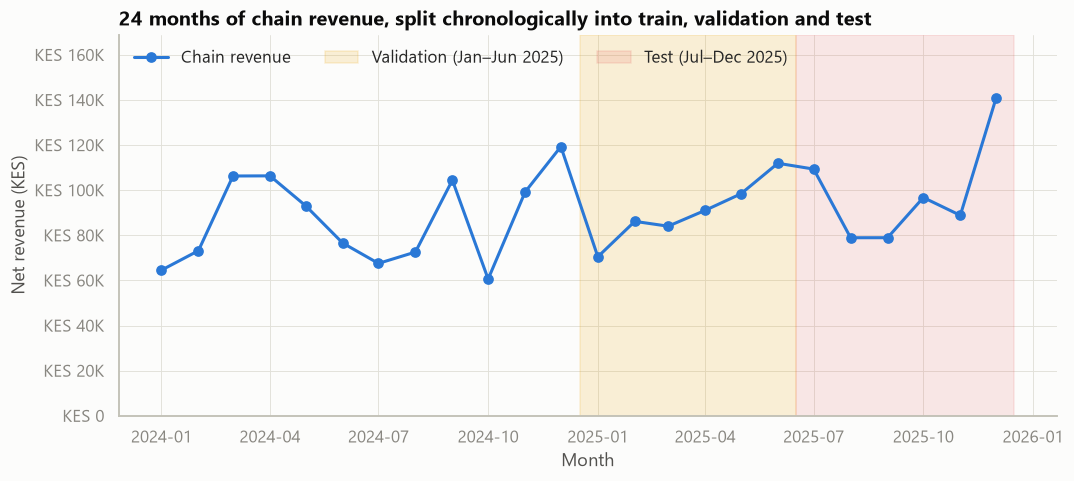

Coefficient of variation: chain 21%; stores 36%–64%


In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(chain.index, chain.values, marker="o", color=style.SERIES[0], label="Chain revenue")
ax.axvspan(fc.VALIDATION_MONTHS[0] - pd.Timedelta(days=15), fc.VALIDATION_MONTHS[-1] + pd.Timedelta(days=15),
           color=style.SERIES[3], alpha=0.15, label="Validation (Jan–Jun 2025)")
ax.axvspan(fc.TEST_MONTHS[0] - pd.Timedelta(days=15), fc.TEST_MONTHS[-1] + pd.Timedelta(days=15),
           color=style.SERIES[7], alpha=0.12, label="Test (Jul–Dec 2025)")
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_ylim(0, chain.max() * 1.2)
ax.set_title("24 months of chain revenue, split chronologically into train, validation and test")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (KES)")
ax.legend(loc="upper left", ncol=3)
style.save(fig, "m6_series_split")
plt.show()

cv_chain = chain.std() / chain.mean()
cv_store = store_month.groupby("town")["revenue"].agg(lambda s: s.std() / s.mean())
print(f"Coefficient of variation: chain {cv_chain:.0%}; stores {cv_store.min():.0%}–{cv_store.max():.0%}")

**What this means for modelling:**
- **Only 24 data points.** That is two seasonal cycles. A seasonal statistical model needs at least two full years
  *before* its first forecast, so it cannot be validated here.
- **The chain series varies about 21% around its average.** Individual stores vary by 36–64%, because single
  electronics sales swing a store's month. Chain revenue is the primary target. Store forecasts are secondary and less reliable.
- **Chronological split:**

  | Period | Months | Purpose |
  |---|---|---|
  | Train | 2024 | Fit the models |
  | Validation | Jan–Jun 2025 | Choose the model and tune it |
  | Test | Jul–Dec 2025 | Final, untouched evaluation |

- **Walk-forward evaluation.** For each month, the models are refitted on all earlier months and forecast one month
  ahead, exactly as they would be used in practice.

## A.2 Features for the Random Forest

The Random Forest learns from a **store × month panel** (6 stores give 6× more training rows than one chain series).
Every feature is known **before** the month starts:

| Feature | Meaning | Why it is not leakage |
|---|---|---|
| `lag_1`, `lag_2`, `lag_3` | Store revenue 1, 2 and 3 months earlier | Past values only |
| `rolling_mean_3`, `rolling_mean_6` | Average of the previous 3 and 6 months | Shifted by one month before averaging |
| `store_level` | Store's average revenue over the training window | Recomputed at each forecast origin from earlier months only |
| `month_sin`, `month_cos`, `is_december`, `is_january` | Position in the year | Calendar facts |
| `holidays_in_month` | Number of public holidays | Gazetted in advance (real data) |
| `promo_days_in_month`, `promo_categories` | Planned campaign days and categories | The promotion plan is set before the month starts |
| `time_index` | Months since January 2024 | Captures slow growth |

In [4]:
panel = fc.build_panel(store_month)
panel[["town", "month", "revenue"] + [f for f in fc.FEATURES if f != "store_level"]].dropna().head(8).round(
    {c: 1 for c in panel.columns if c not in ("town", "month")})

,town,month,revenue,lag_1,lag_2,lag_3,rolling_mean_3,rolling_mean_6,month_sin,month_cos,is_december,is_january,holidays_in_month,promo_days_in_month,promo_categories,time_index
3,Kisumu Town,2024-04-01,"10,447.80","16,670.50","5,000.00","15,525.50","12,398.70","12,398.70",0.90,-0.50,0,0,2,17,3,4
4,Kisumu Town,2024-05-01,"24,070.00","10,447.80","16,670.50","5,000.00","10,706.10","11,911.00",0.50,-0.90,0,0,2,5,1,5
5,Kisumu Town,2024-06-01,"12,170.00","24,070.00","10,447.80","16,670.50","17,062.80","14,342.80",0.00,-1.00,0,0,2,11,1,6
6,Kisumu Town,2024-07-01,"8,621.00","12,170.00","24,070.00","10,447.80","15,562.60","13,980.60",-0.50,-0.90,0,0,0,7,1,7
7,Kisumu Town,2024-08-01,"10,255.00","8,621.00","12,170.00","24,070.00","14,953.70","12,829.90",-0.90,-0.50,0,0,0,7,1,8
8,Kisumu Town,2024-09-01,"6,005.00","10,255.00","8,621.00","12,170.00","10,348.70","13,705.70",-1.00,-0.00,0,0,0,5,1,9
9,Kisumu Town,2024-10-01,"5,240.00","6,005.00","10,255.00","8,621.00","8,293.70","11,928.10",-0.90,0.50,0,0,3,0,0,10
10,Kisumu Town,2024-11-01,"6,425.00","5,240.00","6,005.00","10,255.00","7,166.70","11,060.20",-0.50,0.90,0,0,0,6,1,11


## A.3 Tuning the Random Forest on the validation months

A Random Forest averages many decision trees. With so little data, the key risk is **overfitting** (memorizing noise),
so the grid focuses on how complex each tree may be: `max_depth` and `min_samples_leaf`.
**Selection metric: validation MAE**, chosen before looking at any results.

In [5]:
import itertools
tuning = []
for depth, leaf in itertools.product([3, 5, None], [1, 3, 6]):
    params = {"n_estimators": 300, "max_depth": depth, "min_samples_leaf": leaf}
    preds, _ = fc.walk_forward(store_month, fc.VALIDATION_MONTHS, params)
    tuning.append({"max_depth": str(depth), "min_samples_leaf": leaf,
                   "val_MAE": mt.mae(preds["actual"], preds["Random Forest (store panel)"]),
                   "val_RMSE": mt.rmse(preds["actual"], preds["Random Forest (store panel)"]),
                   "val_MAPE_%": mt.mape(preds["actual"], preds["Random Forest (store panel)"])})
tuning = pd.DataFrame(tuning).sort_values("val_MAE").reset_index(drop=True)
best = tuning.iloc[0]
RF_PARAMS = {"n_estimators": 300, "max_depth": None if best["max_depth"] == "None" else int(best["max_depth"]),
             "min_samples_leaf": int(best["min_samples_leaf"])}
print("Selected Random Forest settings:", RF_PARAMS)
tuning.round(1)

Selected Random Forest settings: {'n_estimators': 300, 'max_depth': 3, 'min_samples_leaf': 1}


,max_depth,min_samples_leaf,val_MAE,val_RMSE,val_MAPE_%
0,3,1,"10,780.90","17,087.30",13.20
1,3,6,"11,418.40","15,298.50",13.60
2,5,6,"11,430.90","15,343.10",13.60
3,None,6,"11,431.20","15,344.20",13.60
4,None,1,"11,506.80","18,006.90",14.20
5,5,1,"12,085.10","18,346.00",14.80
6,3,3,"12,370.70","18,201.10",14.90
7,5,3,"13,040.90","19,130.90",15.70
8,None,3,"13,296.10","19,266.60",16.00


The shallowest trees (`max_depth = 3`) give the lowest validation MAE. This is typical for small, noisy data: simple
trees capture the broad level and seasonality without chasing single electronics sales. The differences between
settings are modest (about KES 10.8K to 13.3K), so the model is not overly sensitive to tuning.

## A.4 Comparing all models on the validation months

,model,MAE,RMSE,MAPE_%
0,Holt (undamped trend),"10,550.80","13,572.40",11.90
1,Holt exponential smoothing,"10,563.80","13,572.90",11.90
2,Random Forest (store panel),"10,780.90","17,087.30",13.20
3,Moving average (3 months),"13,928.60","15,010.60",15.90
4,Naive (last month),"15,762.70","22,073.30",19.60
5,Seasonal naive (last year),"16,194.30","19,202.30",17.30


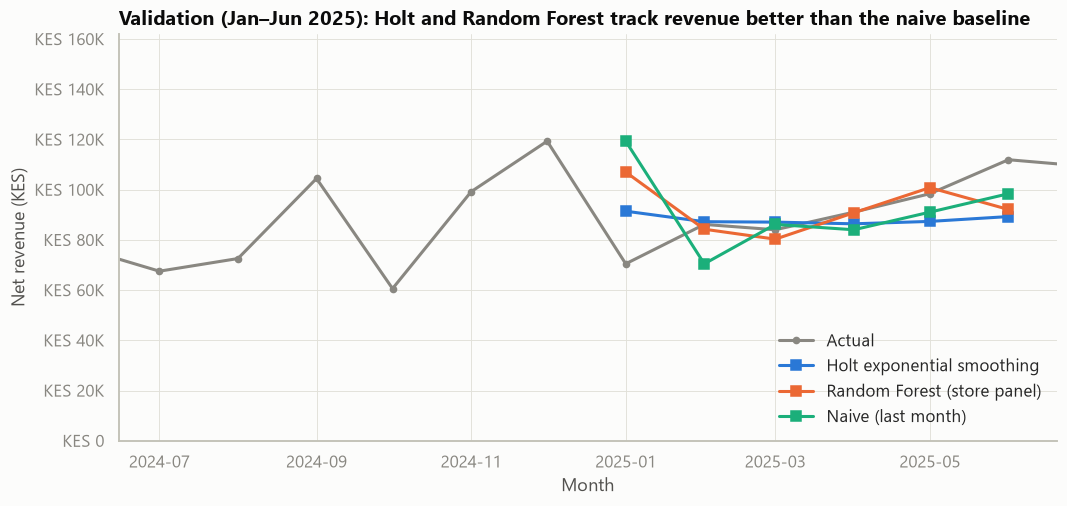

In [6]:
val_preds, val_store = fc.walk_forward(store_month, fc.VALIDATION_MONTHS, RF_PARAMS, holt_damped=True)
holt_undamped, _ = fc.walk_forward(store_month, fc.VALIDATION_MONTHS, RF_PARAMS, holt_damped=False)
val_preds["Holt (undamped trend)"] = holt_undamped["Holt exponential smoothing"]

val_scores = mt.score_table(val_preds)
display(val_scores.round(1))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(chain.index, chain.values, color=style.NEUTRAL, marker="o", markersize=4, label="Actual")
for name, colour in [("Holt exponential smoothing", style.SERIES[0]), ("Random Forest (store panel)", style.SERIES[1]),
                     ("Naive (last month)", style.SERIES[2])]:
    ax.plot(val_preds.index, val_preds[name], marker="s", color=colour, label=name)
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_xlim(pd.Timestamp("2024-06-15"), pd.Timestamp("2025-06-20"))
ax.set_ylim(0, chain.max() * 1.15)
ax.set_title("Validation (Jan–Jun 2025): Holt and Random Forest track revenue better than the naive baseline")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (KES)")
ax.legend(loc="lower right")
style.save(fig, "m6_validation_forecasts")
plt.show()

In [7]:
best_model = val_scores.loc[~val_scores["model"].str.contains("undamped"), "model"].iloc[0]
best_baseline = val_scores[val_scores["model"].isin(["Naive (last month)", "Seasonal naive (last year)",
                                                     "Moving average (3 months)"])].iloc[0]
improvement = 1 - val_scores.set_index("model").loc[best_model, "MAE"] / best_baseline["MAE"]
print(f"Selected model: {best_model}")
print(f"Best baseline: {best_baseline['model']} (MAE {best_baseline['MAE']:,.0f})")
print(f"Validation MAE improvement over the best baseline: {improvement:.0%}")

selection = {"forecast_model": best_model, "rf_params": RF_PARAMS, "holt_damped": True,
             "selection_metric": "validation MAE (Jan-Jun 2025, walk-forward)"}

Selected model: Holt exponential smoothing
Best baseline: Moving average (3 months) (MAE 13,929)
Validation MAE improvement over the best baseline: 24%


**Validation results:**
- **Holt exponential smoothing** has the lowest validation error: MAE about KES 10.6K, MAPE about 12%.
- The **Random Forest** is close behind (about KES 10.8K).
- The best baseline, the 3-month moving average, is about KES 13.9K. Naive and seasonal naive are worse still (KES 15.8K and 16.2K).

**Decisions (fixed before the test period is seen):**
- **Primary forecasting model: Holt exponential smoothing with a damped trend.** The damped and undamped versions
  differ by less than 0.2%. With only 18–23 months of history, a damped trend is the safer assumption, because it does
  not project growth forward indefinitely.
- The **Random Forest** is kept as the challenger, and for **store-level** forecasts, where it can learn shared
  patterns across stores.
- The baselines are kept for the test comparison: a model is only useful if it beats them.

## A.5 What does the Random Forest rely on?

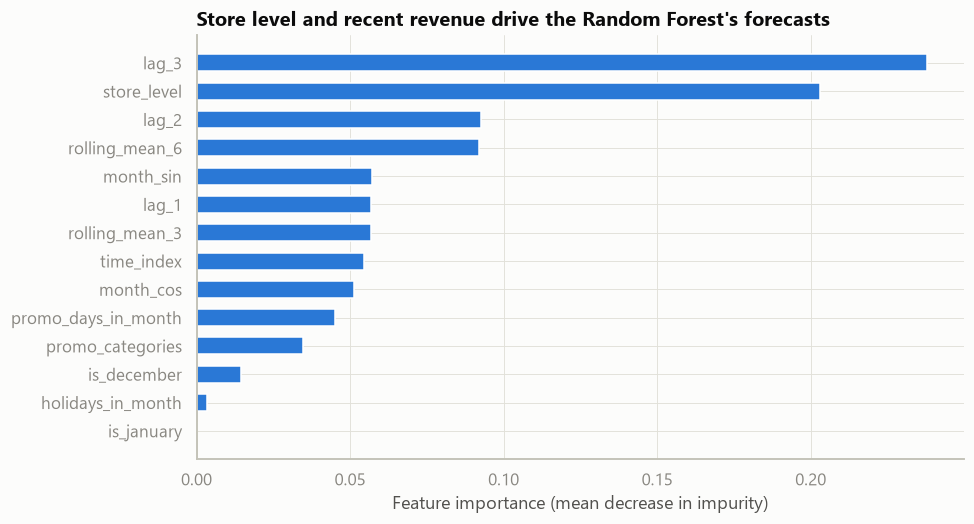

Trained on 54 store-months (Apr–Dec 2024, after lags are available)


In [8]:
rf_model, rf_train = fc.fitted_random_forest(panel, fc.VALIDATION_MONTHS[0], RF_PARAMS)
importance = pd.Series(rf_model.feature_importances_, index=fc.FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance.index, importance.values, color=style.HIGHLIGHT, height=0.6)
ax.set_title("Store level and recent revenue drive the Random Forest's forecasts")
ax.set_xlabel("Feature importance (mean decrease in impurity)")
style.save(fig, "m6_rf_importance")
plt.show()
print(f"Trained on {len(rf_train)} store-months (Apr–Dec 2024, after lags are available)")

**Interpretation:** the forest relies mostly on each **store's usual level** and its **recent revenue** (rolling means
and lags). Calendar and promotion features matter less. With only 54 training rows, the model has little chance to
learn seasonal effects such as December, which is one reason it does not clearly beat Holt.

# Part B: At-risk customers (churn)

## B.1 A defensible inactivity threshold

A customer cannot be called "churned" just because they have not bought for a while; some people simply shop
rarely. We need a threshold based on how long *returning* customers actually wait between purchases.

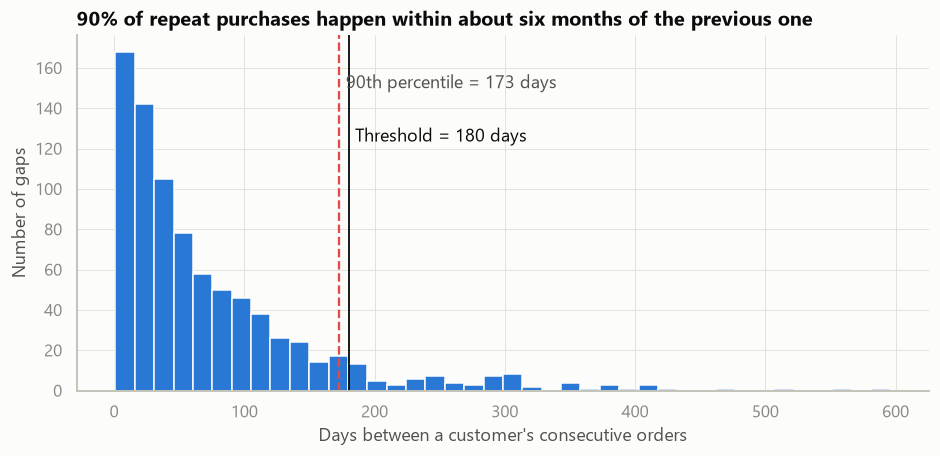

841 gaps from repeat customers. Median 47 days, 75th pct 100, 90th pct 173, 95th pct 250.


In [9]:
gaps = ch.inter_purchase_gaps(orders)
q = gaps.quantile([0.5, 0.75, 0.9, 0.95])
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(gaps, bins=40, color=style.HIGHLIGHT, edgecolor=style.INK["surface"])
ax.axvline(q[0.9], color=style.SERIES[7], linestyle="--", linewidth=1.5)
ax.text(q[0.9] + 5, ax.get_ylim()[1] * 0.85, f"90th percentile = {q[0.9]:.0f} days", color=style.INK["secondary"])
ax.axvline(ch.INACTIVITY_THRESHOLD_DAYS, color=style.INK["primary"], linewidth=1.2)
ax.text(ch.INACTIVITY_THRESHOLD_DAYS + 5, ax.get_ylim()[1] * 0.70, "Threshold = 180 days", color=style.INK["primary"])
ax.set_title("90% of repeat purchases happen within about six months of the previous one")
ax.set_xlabel("Days between a customer's consecutive orders")
ax.set_ylabel("Number of gaps")
style.save(fig, "m6_purchase_gaps")
plt.show()
print(f"{len(gaps)} gaps from repeat customers. Median {q[0.5]:.0f} days, 75th pct {q[0.75]:.0f}, "
      f"90th pct {q[0.9]:.0f}, 95th pct {q[0.95]:.0f}.")

**Threshold decision: 180 days.** The median gap between purchases is 47 days, and **90% of gaps are 173 days or
less**. A customer silent for more than 180 days is behaving unlike 9 in 10 genuine returns, which is strong evidence
they have lapsed. 180 days is also a round, business-friendly "six months", and it matches the RFM "silent > 6 months"
segments in Milestone 4.

**Caveat:** gaps are only observed when a customer comes back *within* the 2-year window, so very long gaps are
under-counted (right-censoring). The true 90th percentile may be a little higher, so 180 days is, if anything, slightly strict.

## B.2 Modelling set-up: out-of-time validation

| | Snapshot date | Features from | Outcome window (label) | Customers |
|---|---|---|---|---|
| **Training** | 31 Dec 2024 | All orders on or before 31 Dec 2024 | Did they buy in Jan–Jun 2025? | Established (2+ orders) |
| **Test** (notebook 07) | 30 Jun 2025 | All orders on or before 30 Jun 2025 | Did they buy in Jul–Dec 2025? | Established (2+ orders) |
| **Scoring** (notebook 07) | 31 Dec 2025 | All orders | Unknown (the future) → current at-risk list | Established (2+ orders) |

**Label:** `churned = 1` if there is **no purchase in the 6 months** after the snapshot. Six months matches the
180-day threshold.

**Why only established customers?** "Drifting away" applies to customers who had a buying habit. Three-quarters of
customers bought only once, so they never established a relationship to lose.

**Why an out-of-time test rather than a random split?** The model is tested on a *later* period than it learned from,
exactly as it would be used. A random split would mix the same time period into training and test, which would flatter the model.

In [10]:
train = ch.add_churn_label(ch.customer_features(sales, ch.TRAIN_SNAPSHOT), sales, ch.TRAIN_SNAPSHOT)
test = ch.add_churn_label(ch.customer_features(sales, ch.TEST_SNAPSHOT), sales, ch.TEST_SNAPSHOT)
print(f"Training snapshot: {len(train)} established customers, churn rate {train['churned'].mean():.1%}")
print(f"Test snapshot:     {len(test)} established customers, churn rate {test['churned'].mean():.1%}")
train[["customer_id"] + ch.FEATURES + ["churned"]].head().round(2)

Training snapshot: 210 established customers, churn rate 84.3%
Test snapshot:     308 established customers, churn rate 80.5%


,customer_id,recency_days,frequency,monetary_kes,tenure_days,avg_order_value,avg_gap_days,overdue_ratio,n_categories,promo_share,loyalty_member,churned
0,C0011,161,4,"3,620.00",328,905.00,55.67,2.89,2,0.00,1,1
1,C0017,45,2,"1,420.00",73,710.00,28.00,1.61,2,0.00,0,1
2,C0030,59,2,800.00,94,400.00,35.00,1.69,2,0.00,1,1
3,C0034,271,2,390.00,321,195.00,50.00,5.42,2,0.00,1,1
4,C0038,40,2,410.00,353,205.00,313.00,0.13,2,0.00,0,1


| Feature | Meaning |
|---|---|
| `recency_days` | Days since last purchase (at the snapshot) |
| `frequency` | Number of orders so far |
| `monetary_kes` | Total spend so far |
| `tenure_days` | Days since first purchase |
| `avg_order_value` | Spend ÷ orders |
| `avg_gap_days` | Customer's own average time between orders |
| `overdue_ratio` | recency ÷ own average gap (above 1 = later than usual) |
| `n_categories` | Number of distinct categories bought |
| `promo_share` | Share of lines bought on promotion |
| `loyalty_member` | 1 if a loyalty member |

**Class imbalance:** about 80–84% of established customers do not buy in a given 6-month window. A model that always
predicted "churned" would be 84% accurate and useless. That is why the evaluation uses **ROC-AUC** (ranking quality)
and **precision and recall**, not accuracy. Logistic regression uses `class_weight="balanced"` so it does not simply
predict the majority class.

## B.3 Model selection with cross-validation on the training snapshot only

Candidates:
1. **Baseline:** rank customers by recency alone (the simplest possible rule).
2. **Logistic regression:** interpretable, and every coefficient has a direction.
3. **Random Forest classifier:** can capture non-linear patterns, but overfits easily on 210 customers.

**Selection method:**
- Score each candidate with **repeated stratified cross-validation ROC-AUC** (5 folds × 10 repeats) on the training
  snapshot only. Repeating the cross-validation smooths out the luck of any single split, which matters because only
  33 training customers actually returned.
- Apply the **one-standard-error rule**: choose the *simplest* candidate whose mean AUC is within one standard error
  of the best. A more complex model has to earn its place with a clear improvement, not a difference inside the noise.
- Order of simplicity: recency rule < logistic regression < Random Forest.

In [11]:
X_train, y_train = train[ch.FEATURES], train["churned"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=config.RANDOM_SEED)
cv_results = {
    "Baseline: recency only": [roc_auc_score(y_train.iloc[v], X_train["recency_days"].iloc[v])
                               for _, v in cv.split(X_train, y_train)],
    "Logistic regression": cross_val_score(ch.logistic_model(), X_train, y_train, cv=cv, scoring="roc_auc"),
    "Random Forest classifier": cross_val_score(ch.random_forest_model(), X_train, y_train, cv=cv, scoring="roc_auc"),
}
n_folds = cv.get_n_splits()
cv_table = pd.DataFrame({name: {"cv_auc_mean": np.mean(v), "cv_auc_std": np.std(v),
                                "standard_error": np.std(v) / np.sqrt(n_folds)}
                         for name, v in cv_results.items()}).T
cv_table["simplicity_rank"] = [1, 2, 3]          # same order as the dictionary above
display(cv_table.sort_values("cv_auc_mean", ascending=False).round(4))

best_auc = cv_table["cv_auc_mean"].max()
best_se = cv_table.loc[cv_table["cv_auc_mean"].idxmax(), "standard_error"]
within_one_se = cv_table[cv_table["cv_auc_mean"] >= best_auc - best_se]
churn_model_name = within_one_se.sort_values("simplicity_rank").index[0]
print(f"Best mean CV AUC = {best_auc:.3f} (standard error {best_se:.3f}); candidates within 1 SE: {list(within_one_se.index)}")
print("Selected (simplest within 1 SE):", churn_model_name)
selection["churn_model"] = churn_model_name
selection["inactivity_threshold_days"] = ch.INACTIVITY_THRESHOLD_DAYS
(config.REPORTS_DIR / "model_selection.json").write_text(json.dumps(selection, indent=2))
print("Saved model choices to reports/model_selection.json for notebook 07.")

,cv_auc_mean,cv_auc_std,standard_error,simplicity_rank
Random Forest classifier,0.75,0.09,0.01,3
Baseline: recency only,0.75,0.10,0.01,1
Logistic regression,0.73,0.11,0.01,2


Best mean CV AUC = 0.753 (standard error 0.013); candidates within 1 SE: ['Baseline: recency only', 'Random Forest classifier']
Selected (simplest within 1 SE): Baseline: recency only
Saved model choices to reports/model_selection.json for notebook 07.


**Result:**
- The three candidates are **statistically tied**: Random Forest 0.753, recency rule 0.749, logistic regression 0.735.
- The fold-to-fold spread (±0.09–0.11) is much larger than the gaps between them, because the training snapshot has
  only 210 established customers, of whom only 33 returned.
- Under the one-standard-error rule, the **simple recency rule is selected**.

**Operational definition of an at-risk customer:** an established customer (2+ orders) with **no purchase for more
than 180 days**.

**Why this is the right call:**
- A more complex model is only worth its cost (explaining it, maintaining it, the risk of overfitting) if it is
  *clearly* better. Here it is not.
- Store managers can apply the rule without any software.
- Notebook 07 still evaluates logistic regression and the Random Forest on the later test period as challengers.
  Their result is reported honestly, but it cannot change the choice, because choosing a model based on test results
  would leak test information into the decision.

Logistic regression is still useful for **interpretation**: its coefficients show which behaviours go together with churn risk.

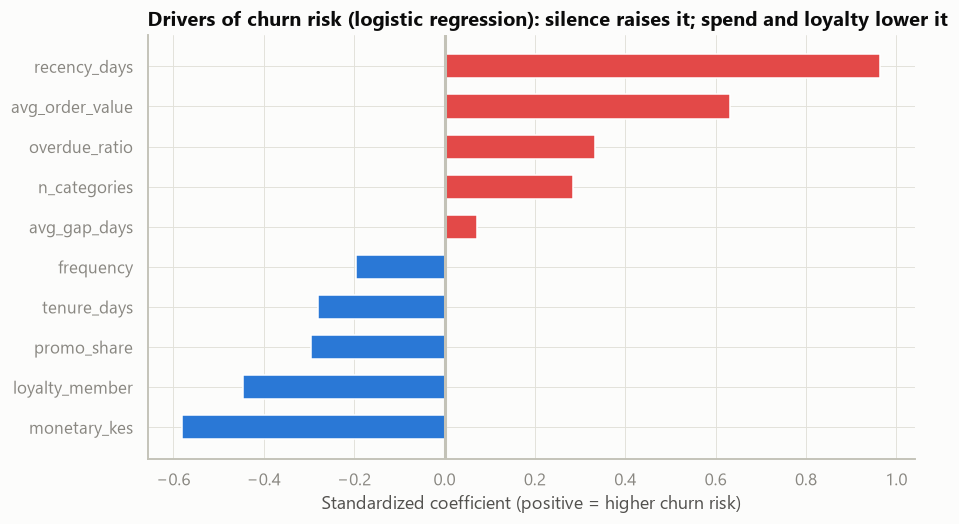

,coefficient
monetary_kes,-0.58
loyalty_member,-0.45
promo_share,-0.30
tenure_days,-0.28
frequency,-0.20
avg_gap_days,0.07
n_categories,0.28
overdue_ratio,0.33
avg_order_value,0.63
recency_days,0.96


In [12]:
# Logistic regression is fitted here to INTERPRET which behaviours go with churn risk,
# even though the simple recency rule is the selected operational model.
final_churn = ch.logistic_model().fit(X_train, y_train)
if True:
    coefs = pd.Series(final_churn[-1].coef_[0], index=ch.FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(coefs.index, coefs.values, color=[style.SERIES[7] if c > 0 else style.SERIES[0] for c in coefs], height=0.6)
    ax.axvline(0, color=style.INK["axis"])
    ax.set_title("Drivers of churn risk (logistic regression): silence raises it; spend and loyalty lower it")
    ax.set_xlabel("Standardized coefficient (positive = higher churn risk)")
    style.save(fig, "m6_churn_coefficients")
    plt.show()
    display(coefs.round(3).to_frame("coefficient"))

**Interpretation of the coefficients.** Features are standardized, so the sizes are comparable.
- **Raises churn risk:** `recency_days` is by far the strongest signal; long silence means likely gone. Others are
  `overdue_ratio` (later than the customer's own rhythm) and `avg_order_value`. That last one is interesting: customers
  who made a few *big* purchases, such as electronics, are less likely to return than habitual grocery shoppers.
- **Lowers churn risk:** total spend, **loyalty membership** and tenure.

**Caution:** `monetary`, `frequency` and `avg_order_value` are related (spend = orders × average order value), so their
individual coefficients should not be over-read. The model's *ranking* of customers is what is used.

The final test evaluation, the comparison with the baseline and the current at-risk list are in **notebook 07**.

In [13]:
config.PROCESSED_DIR.mkdir(exist_ok=True)
val_preds.to_csv(config.PROCESSED_DIR / "forecast_validation_predictions.csv")
print("Saved validation predictions. Model choices:", json.dumps(selection, indent=2))

Saved validation predictions. Model choices: {
  "forecast_model": "Holt exponential smoothing",
  "rf_params": {
    "n_estimators": 300,
    "max_depth": 3,
    "min_samples_leaf": 1
  },
  "holt_damped": true,
  "selection_metric": "validation MAE (Jan-Jun 2025, walk-forward)",
  "churn_model": "Baseline: recency only",
  "inactivity_threshold_days": 180
}
